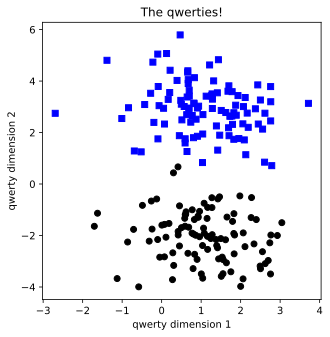

In [2]:
# import libraries
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

# For class implementation
import torch.nn.functional as F

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')


# create data

nPerClust = 100
blur = 1

A = [  1,  3 ]
B = [  1, -2 ]

# generate data
a = [ A[0]+np.random.randn(nPerClust)*blur , A[1]+np.random.randn(nPerClust)*blur ]
b = [ B[0]+np.random.randn(nPerClust)*blur , B[1]+np.random.randn(nPerClust)*blur ]

# true labels
labels_np = np.vstack((np.zeros((nPerClust,1)),np.ones((nPerClust,1))))

# concatanate into a matrix
data_np = np.hstack((a,b)).T

# convert to a pytorch tensor
data = torch.tensor(data_np).float()
labels = torch.tensor(labels_np).float()

# show the data
fig = plt.figure(figsize=(5,5))
plt.plot(data[np.where(labels==0)[0],0],data[np.where(labels==0)[0],1],'bs')
plt.plot(data[np.where(labels==1)[0],0],data[np.where(labels==1)[0],1],'ko')
plt.title('The qwerties!')
plt.xlabel('qwerty dimension 1')
plt.ylabel('qwerty dimension 2')
plt.show()


In [8]:
class NeuralNetwork(nn.Module):
  def __init__(self):
    super().__init__()
    self.input = nn.Linear(2,16)
    self.hidden = nn.Linear(16,1)
    self.output = nn.Linear(1,1)


  def forward(self,x):
    x = self.input(x)
    x = F.relu(x)
    x = self.hidden(x)
    x = F.relu(x)
    x = self.output(x)
    x = torch.sigmoid(x)
    return x

In [9]:
ANNclassify= NeuralNetwork()

#Learning rate
learningRate = 0.01
#Loss function
lossfun = nn.BCELoss()
# optimizer
optimizer = torch.optim.SGD(ANNclassify.parameters(),lr=learningRate)


In [10]:
# a function that trains the model

# a fixed parameter
numepochs = 1000

# initialize losses
losses = torch.zeros(numepochs)

# loop over epochs
for epochi in range(numepochs):

  # forward pass
  yHat = ANNclassify(data)

  # compute loss
  loss = lossfun(yHat,labels)
  losses[epochi] = loss

  # backprop
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()



# final forward pass
predictions = ANNclassify(data)

# compute the predictions and report accuracy
# NOTE: Wasn't this ">0" previously?!?! - Because of BCE loss function(Sigmoid varies between 0 and 1)
totalacc = 100*torch.mean(((predictions>.5) == labels).float())



Final accuracy: 99%


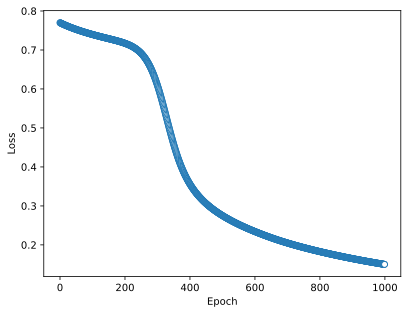

In [11]:
# report accuracy
print('Final accuracy: %g%%' %totalacc)


# show the losses
plt.plot(losses.detach(),'o',markerfacecolor='w',linewidth=.1)
plt.xlabel('Epoch'), plt.ylabel('Loss')
plt.show()